# Code Notebook for Data 275P Homework 2

In [182]:
import numpy as np
import matplotlib.pyplot as plt

import requests                                      # reading data
from io import StringIO

<hr style="height: 3px;">

### Load the data

In [183]:
url = 'https://www.ics.uci.edu/~ihler/classes/data275P/data/mcycle.txt'
nTrain = 40

with requests.get(url) as link:
    datafile = StringIO(link.text)
    mcycle_data = np.genfromtxt(datafile,delimiter=' ')
    x_train_raw, y_train = mcycle_data[:nTrain,0], mcycle_data[:nTrain,-1]
    x_test_raw, y_test = mcycle_data[nTrain:,0], mcycle_data[nTrain:,-1]

# x_train: training matrix: 40 data points, recorded time (sec)
# y_train: training target values: 40 data points, acceleration values
# x_test: test matrix: 53 data points, recorded time (sec)
# y_test: test target values: 53 data points, acceleration values
## Note: we will rescale the _raw data before using it in the problem...

## We'll plot our predicted function values on a regular, dense grid:
n_grid = 1000
x_grid_raw = np.linspace(0,60,n_grid)

In [184]:
# We will re-scale the input features so that they lie in [-1,1] for numerical stability:
## Estimate the transformation on the training data (only!)
scale = (np.max(x_train_raw)-np.min(x_train_raw))/2  ## range of x_train
shift = scale                                ## center of x_train range
## Then apply the same transformation to all the data
x_train = (x_train_raw - shift)/scale
x_test = (x_test_raw - shift)/scale
x_grid = (x_grid_raw - shift)/scale 

### Helper functions

We will use two sets of basis functions for our linear regression models: polynomial, and radial basis

In [185]:
def basis_poly(x, order):
    ''' Generates a polynomial basis expansion of x for a specific order

        Parameters:
            x: (N,) array of values to compute the basis functions for
            order: [Integer] Order of the basis function

        Returns
            (N, order+1) array of the basis function for each input in x
    '''
    phi = np.zeros(shape=(x.shape[0], order+1))
    for p in range(order+1):
        phi[:, p] = x**p

    return phi

In [186]:
def basis_radial(x, order):
    ''' Generates a radial basis expansion of x for a given order

        Parameters:
            x: (N,) array of values to compute the basis functions for
            order: [Integer] Order of the basis function

        Returns
            (N, order+1) array of the basis function for each input in x
    '''
    phi = np.zeros((x.shape[0],order+1))
    phi[:,0] = 1.0
    centers = np.linspace(-1,1,order+2)
    bandwidth = centers[1]-centers[0]
    for i in range(1,order+1):
        phi[:,i] = np.exp(-0.5 * ((x-centers[i])/bandwidth)**2)
    return phi


Now, we can use these basis functions as features for our linear regression model.

### Example usage:

In [187]:
# Compute the feature covariance and target cross-covariance
phi_train = basis_poly(x_train, 1)
a = phi_train.T @ phi_train
b = phi_train.T @ y_train
weights = np.linalg.lstsq(a,b, rcond=-1)[0] # Used instead of matrix inversion for numerical stability

After selecting the ML weight parameters, we can predict:

In [188]:
# Given w, make predictions at training and test points, and on dense grid
yhat_train = phi_train @ weights

phi_test = basis_poly(x_test, 1)
yhat_test = phi_test @ weights 

phi_grid = basis_poly(x_grid, 1)
yhat_grid = phi_grid @ weights

... compute our training and test error ...

In [189]:
# Root-mean-squared error metric on training and test data for this function
train_err = np.sqrt(np.mean((y_train - yhat_train)**2))
test_err  = np.sqrt(np.mean((y_test - yhat_test)**2))
print(f'Train RMSE: {train_err}; Test RMSE: {test_err}')

Train RMSE: 53.833732879860406; Test RMSE: 47.151864342741874


... and plot our predicted curve alongside the data:

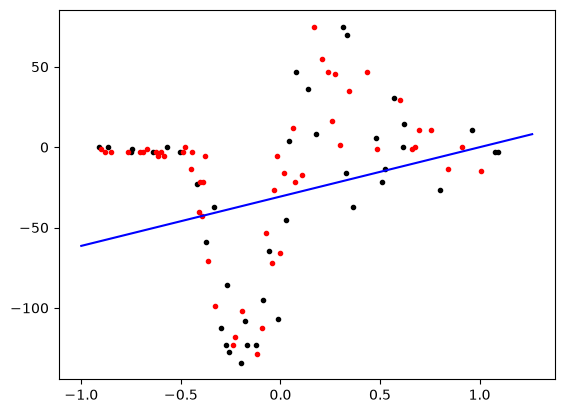

In [190]:
# Plot ML estimate on dense grid, along with training & test data
plt.plot(x_train, y_train, 'k.')
plt.plot(x_test, y_test, 'r.')
plt.plot(x_grid, yhat_grid, 'b-')
plt.show()

<hr style="height: 3px;">

### Your functions (to be completed)
Update/complete the code in these functions for your assignment. Don't change the function names or signatures, as these will be used by the autograder.

Feel free to create additional cells to create the plots and results you need for your PDF solution.

### Problem 1
Complete the function to estimate the ML/MAP weights given a (basis transformed) dataset. For Problem 1 you can ignore lambda, but you will need to come back and update the function to complete Problem 2.

In [191]:
def compute_weights(phi_train, y_train, lambda_val=0.):
    """
    Compute the ML or MAP estimates of weights for linear regression.

    Args:
        phi_train: Training basis matrix (size NxM, for N training data and M features)
        y_train: Training target labels (size Nx1)
        lambda_val: Regularization parameter (alpha/beta) for MAP weight estimation.
                    lambda_val = 0 for ML estimation

    Returns:
        weights: Computed regression weights (size Mx1)
    """

    M = phi_train.shape[1]
    A = np.matmul(phi_train.T, phi_train) + lambda_val * np.eye(M)
    b = np.matmul(phi_train.T, y_train)
    weights = np.linalg.lstsq(A, b, rcond=-1)[0]

    return weights

Complete a function to iterate over possible orders and evaluate their training & test RMSE:

In [192]:
def compute_errors_for_models(orders_to_try, x_train, y_train, x_test, y_test,
                                     x_grid, basis_func, lambda_var):
    """
    Computes model weights, predictions, and errors for multiple model orders.

    Parameters:
    ----------
    orders_to_try : list
        List of model orders to evaluate
    x_train : numpy.ndarray
        (scaled) training input features
    y_train : numpy.ndarray
        Training target values
    x_test : numpy.ndarray
        (scaled) testing input features
    y_test : numpy.ndarray
        Testing target values
    x_grid : numpy.ndarray
        (scaled) grid points for visualization
    basis_func : callable
        Function to compute basis functions
    lambda_var : float
        Regularization parameter (0 for ML weight estimates)

    Returns:
    -------
    weights_all : numpy.ndarray
        Weights for all model orders
    func_all : numpy.ndarray
        Predictions on grid for all model orders
    train_err : numpy.ndarray
        Training errors for all model orders
    test_err : numpy.ndarray
        Testing errors for all model orders
    """
    K = len(orders_to_try)
    weights_all = np.zeros((max(orders_to_try)+1,K))
    func_all = np.zeros((x_grid.shape[0],K))
    train_err = np.zeros((K,))
    test_err = np.zeros((K,))

    for idx,order in enumerate(orders_to_try):
        phi_train = basis_func(x_train,order)
        phi_test  = basis_func(x_test,order)
        phi_grid  = basis_func(x_grid,order)
        
        weights = compute_weights(phi_train, y_train, lambda_var)
        weights_all[:len(weights),idx] = weights
        
        # Compute predictions on grid
        # and compute errors
        func_all[:,idx] = phi_grid @ weights
        train_err[idx] = np.sqrt(np.mean((y_train - phi_train @ weights)**2))
        test_err[idx]  = np.sqrt(np.mean((y_test  - phi_test  @ weights)**2))


    return weights_all, func_all, train_err, test_err

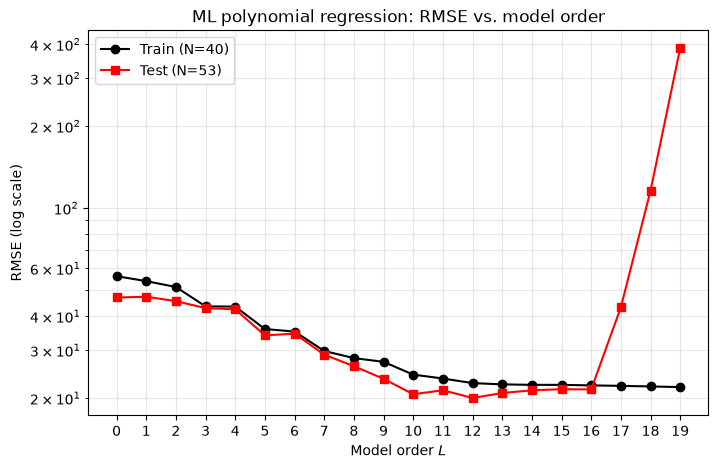

Smallest training error: L = 19 (RMSE = 21.952)
Smallest test error:     L = 12 (RMSE = 20.018)


In [193]:
# ML estimates for model orders L = 0..19: train & test RMSE vs. model order
orders = np.arange(20)
train_rmse = np.zeros(len(orders))
test_rmse  = np.zeros(len(orders))

for i, L in enumerate(orders):
    phi_tr = basis_poly(x_train, L)
    phi_te = basis_poly(x_test, L)
    w = compute_weights(phi_tr, y_train)      # lambda = 0 -> ML estimate
    train_rmse[i] = np.sqrt(np.mean((y_train - phi_tr @ w)**2))
    test_rmse[i]  = np.sqrt(np.mean((y_test  - phi_te @ w)**2))

plt.figure(figsize=(8, 5))
plt.semilogy(orders, train_rmse, 'ko-', label='Train (N=40)')
plt.semilogy(orders, test_rmse,  'rs-', label='Test (N=53)')
plt.xlabel('Model order $L$')
plt.ylabel('RMSE (log scale)')
plt.title('ML polynomial regression: RMSE vs. model order')
plt.xticks(orders)
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

best_train = orders[np.argmin(train_rmse)]
best_test  = orders[np.argmin(test_rmse)]
print(f'Smallest training error: L = {best_train} (RMSE = {train_rmse.min():.3f})')
print(f'Smallest test error:     L = {best_test} (RMSE = {test_rmse.min():.3f})')

In [194]:
# Test: ML weight estimate for a polynomial model of order L = 5
L = 5
phi_train_L5 = basis_poly(x_train, L)
w_ml = compute_weights(phi_train_L5, y_train)

# Shapes: N x (L+1) basis matrix, one weight per basis function
assert phi_train_L5.shape == (x_train.shape[0], L+1)
assert w_ml.shape == (L+1,)

# Matches the hint's lstsq on the normal equations
a = phi_train_L5.T @ phi_train_L5
b = phi_train_L5.T @ y_train
assert np.allclose(w_ml, np.linalg.lstsq(a, b, rcond=-1)[0])

# Matches least squares directly on phi, and numpy's polynomial fit (reversed: polyfit lists highest power first)
assert np.allclose(w_ml, np.linalg.lstsq(phi_train_L5, y_train, rcond=-1)[0])
assert np.allclose(w_ml, np.polyfit(x_train, y_train, L)[::-1])

print('All checks passed. ML weights (w_0 ... w_5):', np.round(w_ml, 4))

All checks passed. ML weights (w_0 ... w_5): [ -57.03    238.6074  253.8208 -823.7175 -268.5791  623.0245]


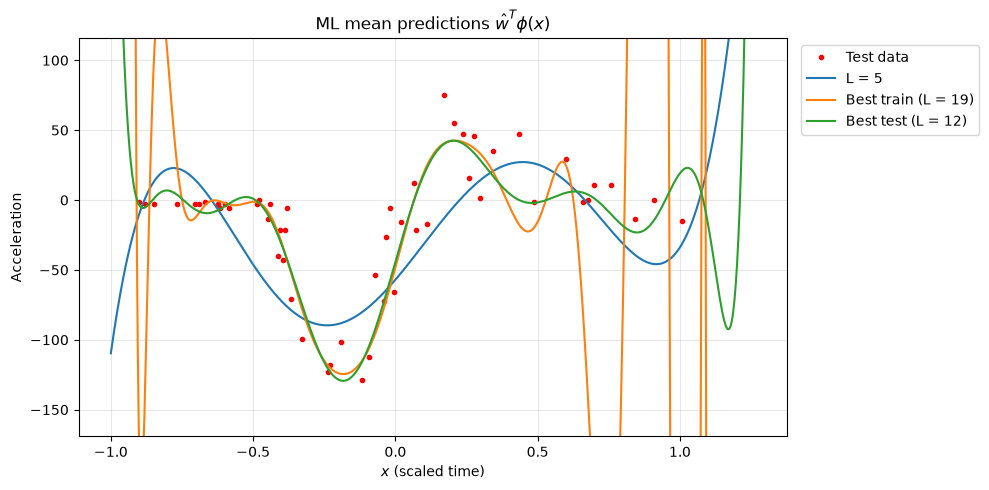

In [195]:
# Plot test data and ML mean predictions w^T phi(x) on the dense grid for three models
# (uses best_train / best_test from the RMSE cell above)
models = {
    'L = 5': 5,
    f'Best train (L = {best_train})': best_train,
    f'Best test (L = {best_test})': best_test,
}

plt.figure(figsize=(10, 5))
plt.plot(x_test, y_test, 'r.', label='Test data')
for label, L in models.items():
    w = compute_weights(basis_poly(x_train, L), y_train)
    plt.plot(x_grid, basis_poly(x_grid, L) @ w, '-', label=label)

# High-order fits blow up near the edges, so clip the y-axis to the data range
pad = 0.2 * (y_test.max() - y_test.min())
plt.ylim(y_test.min() - pad, y_test.max() + pad)
plt.xlabel('$x$ (scaled time)')
plt.ylabel('Acceleration')
plt.title(r'ML mean predictions $\hat{w}^T\phi(x)$')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Problem 1, part 3: Radial basis functions
Repeat parts (1)–(2) using `basis_radial` (centers evenly spaced in [-1, 1], bandwidth = spacing between centers) for model orders L = 0, 5, 10, 15, 20, 25.

In [196]:
# Test: ML weight estimate for a radial basis model of order L = 5
L = 5
phi_train_rbf_L5 = basis_radial(x_train, L)
w_ml_rbf = compute_weights(phi_train_rbf_L5, y_train)

# Shapes: N x (L+1) basis matrix, one weight per basis function
assert phi_train_rbf_L5.shape == (x_train.shape[0], L+1)
assert w_ml_rbf.shape == (L+1,)

# Matches least squares directly on phi
assert np.allclose(w_ml_rbf, np.linalg.lstsq(phi_train_rbf_L5, y_train, rcond=-1)[0])

print('All checks passed. ML RBF weights (w_0 ... w_5):', np.round(w_ml_rbf, 4))

All checks passed. ML RBF weights (w_0 ... w_5): [  42.9749    9.8683  -66.4444 -145.0836  168.6443 -137.6958]


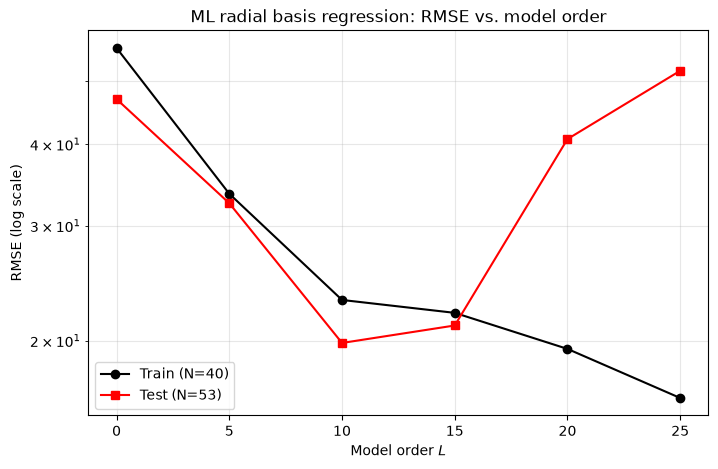

Smallest training error: L = 25 (RMSE = 16.328)
Smallest test error:     L = 10 (RMSE = 19.829)


In [197]:
# ML estimates for radial basis models of order L = 0, 5, ..., 25: train & test RMSE vs. model order
orders_rbf = np.arange(0, 30, 5)
train_rmse_rbf = np.zeros(len(orders_rbf))
test_rmse_rbf  = np.zeros(len(orders_rbf))

for i, L in enumerate(orders_rbf):
    phi_tr = basis_radial(x_train, L)
    phi_te = basis_radial(x_test, L)
    w = compute_weights(phi_tr, y_train)      # lambda = 0 -> ML estimate
    train_rmse_rbf[i] = np.sqrt(np.mean((y_train - phi_tr @ w)**2))
    test_rmse_rbf[i]  = np.sqrt(np.mean((y_test  - phi_te @ w)**2))

plt.figure(figsize=(8, 5))
plt.semilogy(orders_rbf, train_rmse_rbf, 'ko-', label='Train (N=40)')
plt.semilogy(orders_rbf, test_rmse_rbf,  'rs-', label='Test (N=53)')
plt.xlabel('Model order $L$')
plt.ylabel('RMSE (log scale)')
plt.title('ML radial basis regression: RMSE vs. model order')
plt.xticks(orders_rbf)
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

best_train_rbf = orders_rbf[np.argmin(train_rmse_rbf)]
best_test_rbf  = orders_rbf[np.argmin(test_rmse_rbf)]
print(f'Smallest training error: L = {best_train_rbf} (RMSE = {train_rmse_rbf.min():.3f})')
print(f'Smallest test error:     L = {best_test_rbf} (RMSE = {test_rmse_rbf.min():.3f})')

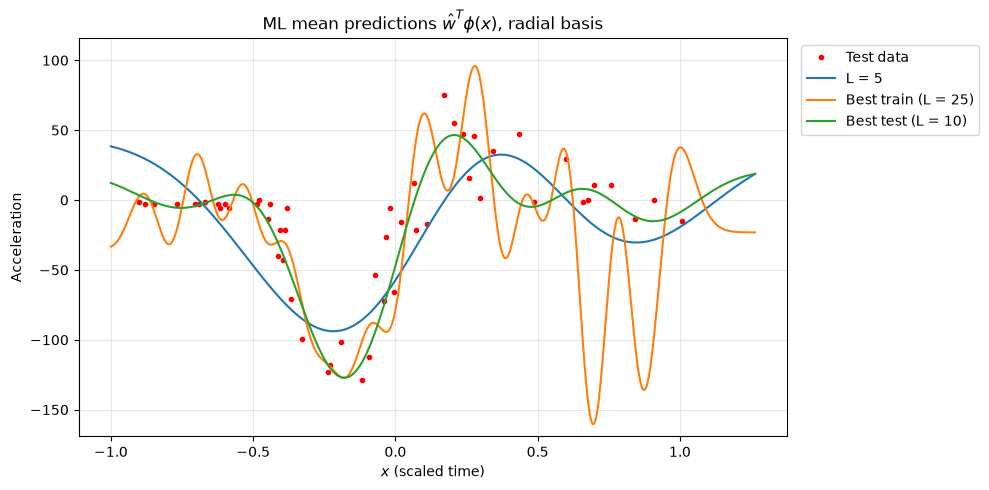

In [198]:
# Plot test data and ML mean predictions w^T phi(x) on the dense grid for three radial basis models
# (uses best_train_rbf / best_test_rbf from the RMSE cell above)
models_rbf = {
    'L = 5': 5,
    f'Best train (L = {best_train_rbf})': best_train_rbf,
    f'Best test (L = {best_test_rbf})': best_test_rbf,
}

plt.figure(figsize=(10, 5))
plt.plot(x_test, y_test, 'r.', label='Test data')
for label, L in models_rbf.items():
    w = compute_weights(basis_radial(x_train, L), y_train)
    plt.plot(x_grid, basis_radial(x_grid, L) @ w, '-', label=label)

# Use the same y-axis range as the polynomial plot for easy comparison
pad = 0.2 * (y_test.max() - y_test.min())
plt.ylim(y_test.min() - pad, y_test.max() + pad)
plt.xlabel('$x$ (scaled time)')
plt.ylabel('Acceleration')
plt.title(r'ML mean predictions $\hat{w}^T\phi(x)$, radial basis')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Problem 1, part 4: Held-out point (x = 57.6, y = 10.7)
Predict the excluded point with the best-test polynomial and radial basis models from above.

Scaled x = 1.174  (train x range [-0.909, 1.091], test x range [-0.902, 1.008])
Polynomial (L = 12):   prediction = -92.040, RMSE = 102.740
Radial basis (L = 10): prediction = 12.957, RMSE = 2.257


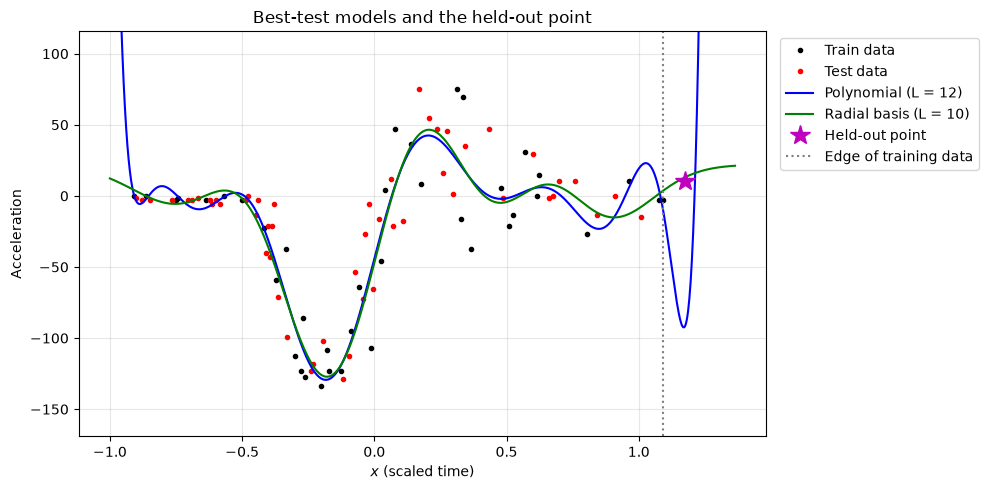

In [199]:
# Held-out point, scaled with the same transformation as the training data
x_out_raw, y_out = 57.6, 10.7
x_out = np.array([(x_out_raw - shift)/scale])

# Best-test models (uses best_test / best_test_rbf from the RMSE cells above)
w_poly = compute_weights(basis_poly(x_train, best_test), y_train)
w_rbf  = compute_weights(basis_radial(x_train, best_test_rbf), y_train)
yhat_out_poly = (basis_poly(x_out, best_test) @ w_poly)[0]
yhat_out_rbf  = (basis_radial(x_out, best_test_rbf) @ w_rbf)[0]

# RMSE of a single point is just the absolute error
rmse_out_poly = np.sqrt((y_out - yhat_out_poly)**2)
rmse_out_rbf  = np.sqrt((y_out - yhat_out_rbf)**2)

print(f'Scaled x = {x_out[0]:.3f}  (train x range [{x_train.min():.3f}, {x_train.max():.3f}], '
      f'test x range [{x_test.min():.3f}, {x_test.max():.3f}])')
print(f'Polynomial (L = {best_test}):   prediction = {yhat_out_poly:.3f}, RMSE = {rmse_out_poly:.3f}')
print(f'Radial basis (L = {best_test_rbf}): prediction = {yhat_out_rbf:.3f}, RMSE = {rmse_out_rbf:.3f}')

# Plot both best-test fits over a grid extended past the held-out point
x_ext = np.linspace(x_grid.min(), max(x_grid.max(), x_out[0]) + 0.1, n_grid)
plt.figure(figsize=(10, 5))
plt.plot(x_train, y_train, 'k.', label='Train data')
plt.plot(x_test, y_test, 'r.', label='Test data')
plt.plot(x_ext, basis_poly(x_ext, best_test) @ w_poly, 'b-', label=f'Polynomial (L = {best_test})')
plt.plot(x_ext, basis_radial(x_ext, best_test_rbf) @ w_rbf, 'g-', label=f'Radial basis (L = {best_test_rbf})')
plt.plot(x_out, [y_out], 'm*', markersize=15, label='Held-out point')
plt.axvline(x_train.max(), color='gray', ls=':', label='Edge of training data')
pad = 0.2 * (y_test.max() - y_test.min())
plt.ylim(y_test.min() - pad, y_test.max() + pad)
plt.xlabel('$x$ (scaled time)')
plt.ylabel('Acceleration')
plt.title('Best-test models and the held-out point')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Problem 2: Bayesian Linear Regression

If you did not implement MAP estimation in problem 1, go back and update `compute_weights` to accept a regularization penalty lambda.

Then, write a function to iterate across lambda values and evaluate their resulting RMSE:

In [200]:
def compute_errors_across_lambda(phi_train, y_train, phi_test, y_test, x_grid, phi_grid, lambda_var):
    """
    Compute MAP weights, predictions, and errors for different lambda values.

    Args:
        phi_train: Training basis matrix
        y_train: Training targets
        phi_test: Test basis matrix
        y_test: Test targets
        x_grid: Grid points for visualization
        phi_grid: Grid basis matrix for visualization
        lambda_var: Array of regularization parameters (alpha/beta)

    Returns:
        weights_all: MAP weights for each lambda
        func_all: Predictions on grid points for each lambda
        train_err: Training errors for each lambda
        test_err: Test errors for each lambda
    """
    # Compute ML/MAP least squares fit for each model
    # Also compute corresponding training and test accuracy
    K = lambda_var.shape[0]
    M = phi_train.shape[1]
    weights_all = np.zeros((M,K))
    func_all    = np.zeros((x_grid.shape[0],K))
    train_err   = np.zeros((K,))
    test_err    = np.zeros((K,))

    for lambda_idx in range(K):
        # Call the function
        weights = compute_weights(phi_train, y_train, lambda_var[lambda_idx])

        weights_all[:M,lambda_idx] = weights
        # Compute predictions on grid
        # and compute errors
        func_all[:,lambda_idx] = phi_grid @ weights
        train_err[lambda_idx] = np.sqrt(np.mean((y_train - phi_train @ weights)**2))
        test_err[lambda_idx]  = np.sqrt(np.mean((y_test  - phi_test  @ weights)**2))

    return weights_all, func_all, train_err, test_err


Complete the following function to generate samples of weights w from the posterior distribution, and then return the predicted function (evaluated on the dense grid) associated with each of these samples.

In [201]:
def generate_posterior_samples(phi_train, y_train, phi_grid, alpha, beta, num_samples=10):
    """
    Generate samples from the Gaussian posterior distribution.
   
    Args:
        phi_train: Training basis matrix (size NxM)
        y_train: Training target labels (size Nx1)
        phi_grid: Grid basis matrix for visualization (size GxM)
        alpha: Prior inverse-variance hyperparameter alpha (float)
        beta:  Likelihood inverse-variance hyperparameter beta (float)
        num_samples: Number of samples to generate (default: 10)
        
    Returns:
        func_samples: Matrix of function samples (size G x num_samples)
        post_mean: Posterior mean (size Mx1)
        post_inv_covar: Posterior inverse covariance matrix (size MxM)
    """
    # Calculate posterior inverse covariance and mean
    post_inv_covar = alpha * np.eye(phi_train.shape[1]) + beta * phi_train.T @ phi_train
    post_mean = beta * np.linalg.solve(post_inv_covar, phi_train.T @ y_train)

    # Calculate posterior covariance (ensure symmetry for numerical stability)
    post_covar = np.linalg.inv(post_inv_covar)
    post_covar = 0.5 * (post_covar + post_covar.T)

    # Generate samples from posterior (use np.random.multivariate_normal)
    w_samples = np.random.multivariate_normal(post_mean, post_covar, size=num_samples)  # (num_samples, M)
    func_samples = phi_grid @ w_samples.T                                               # (G, num_samples)

    return func_samples, post_mean, post_inv_covar

### Problem 2, part 2: MAP estimates vs. α (polynomial, L = 50)
Fix β = 0.0025 and sweep 100 values of α from 10⁻⁸ to 1. The MAP weights use λ = α/β in `compute_weights`.

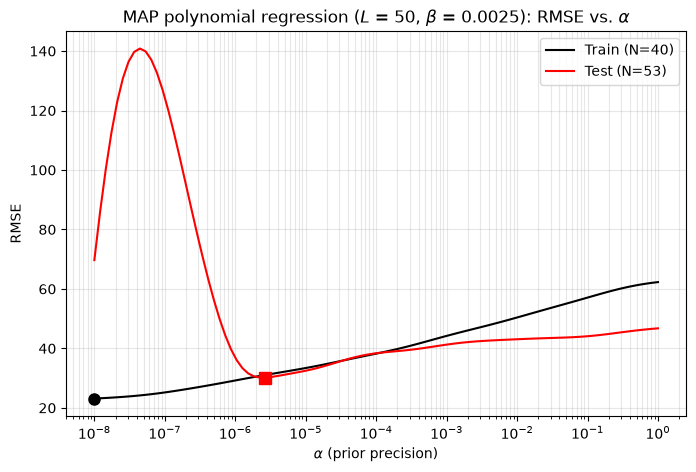

Smallest training error: alpha = 1.000e-08 (RMSE = 23.132)
Smallest test error:     alpha = 2.656e-06 (RMSE = 30.174)


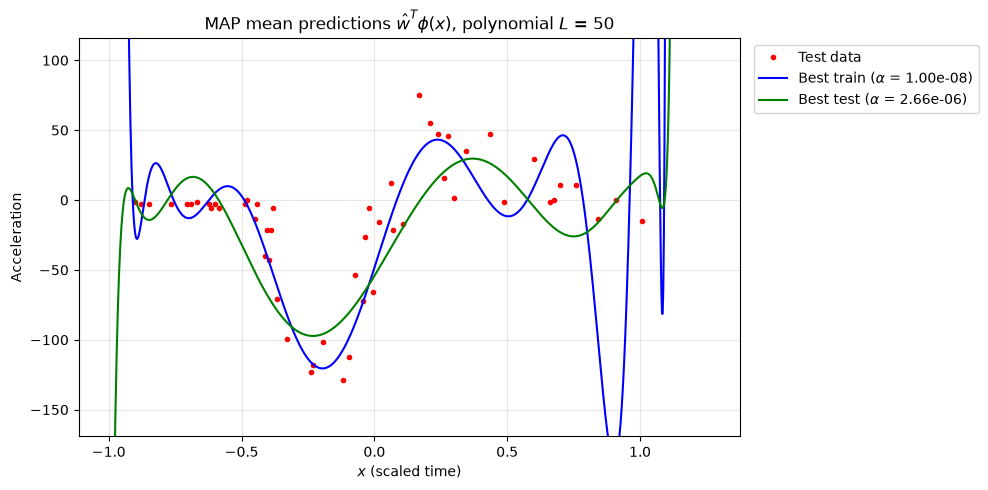

In [202]:
# MAP estimates for a polynomial model of order L = 50 across alpha: train & test RMSE vs. alpha
L_map = 50
beta = 0.0025
alpha = np.logspace(-8, 0, 100)

phi_tr = basis_poly(x_train, L_map)
phi_te = basis_poly(x_test, L_map)
phi_gr = basis_poly(x_grid, L_map)

train_rmse_map = np.zeros(len(alpha))
test_rmse_map  = np.zeros(len(alpha))
func_map       = np.zeros((x_grid.shape[0], len(alpha)))

for i, a in enumerate(alpha):
    w = compute_weights(phi_tr, y_train, a / beta)   # lambda = alpha/beta -> MAP estimate
    train_rmse_map[i] = np.sqrt(np.mean((y_train - phi_tr @ w)**2))
    test_rmse_map[i]  = np.sqrt(np.mean((y_test  - phi_te @ w)**2))
    func_map[:, i]    = phi_gr @ w

best_train_idx = np.argmin(train_rmse_map)
best_test_idx  = np.argmin(test_rmse_map)
best_train_alpha = alpha[best_train_idx]
best_test_alpha  = alpha[best_test_idx]

plt.figure(figsize=(8, 5))
plt.semilogx(alpha, train_rmse_map, 'k-', label='Train (N=40)')
plt.semilogx(alpha, test_rmse_map,  'r-', label='Test (N=53)')
plt.semilogx(best_train_alpha, train_rmse_map[best_train_idx], 'ko', markersize=8)
plt.semilogx(best_test_alpha,  test_rmse_map[best_test_idx],  'rs', markersize=8)
plt.xlabel(r'$\alpha$ (prior precision)')
plt.ylabel('RMSE')
plt.title(rf'MAP polynomial regression ($L$ = {L_map}, $\beta$ = {beta}): RMSE vs. $\alpha$')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

print(f'Smallest training error: alpha = {best_train_alpha:.3e} (RMSE = {train_rmse_map[best_train_idx]:.3f})')
print(f'Smallest test error:     alpha = {best_test_alpha:.3e} (RMSE = {test_rmse_map[best_test_idx]:.3f})')

# Plot test data and MAP mean predictions w^T phi(x) for the best-train and best-test alphas
plt.figure(figsize=(10, 5))
plt.plot(x_test, y_test, 'r.', label='Test data')
plt.plot(x_grid, func_map[:, best_train_idx], 'b-', label=rf'Best train ($\alpha$ = {best_train_alpha:.2e})')
plt.plot(x_grid, func_map[:, best_test_idx],  'g-', label=rf'Best test ($\alpha$ = {best_test_alpha:.2e})')

pad = 0.2 * (y_test.max() - y_test.min())
plt.ylim(y_test.min() - pad, y_test.max() + pad)
plt.xlabel('$x$ (scaled time)')
plt.ylabel('Acceleration')
plt.title(rf'MAP mean predictions $\hat{{w}}^T\phi(x)$, polynomial $L$ = {L_map}')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Problem 2, part 3: MAP estimates vs. α (radial basis, L = 50)
Repeat part 2 with `basis_radial` (same β = 0.0025 and α grid).

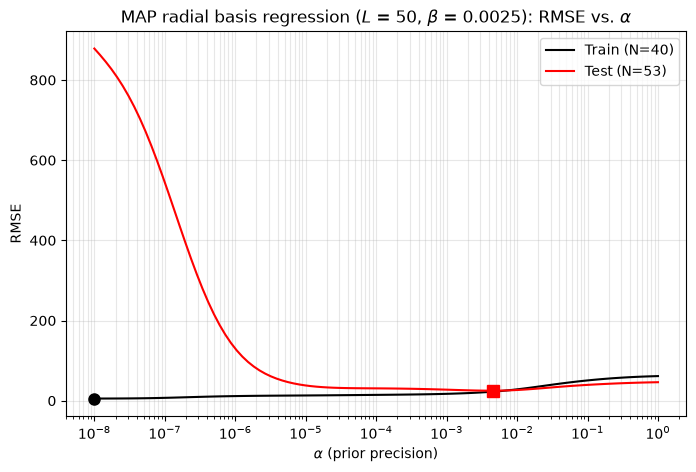

Smallest training error: alpha = 1.000e-08 (RMSE = 5.311)
Smallest test error:     alpha = 4.535e-03 (RMSE = 24.947)


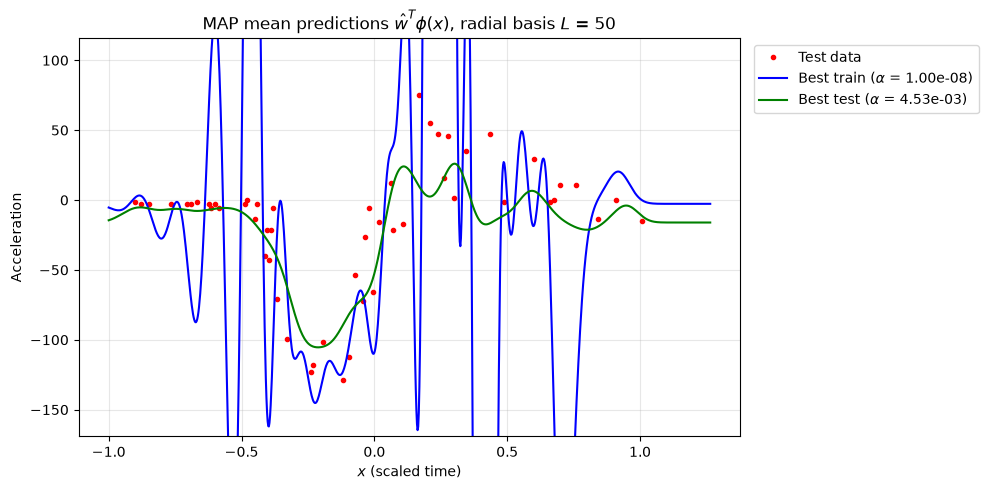

In [203]:
# MAP estimates for a radial basis model of order L = 50 across alpha: train & test RMSE vs. alpha
# (uses L_map, beta, alpha from the part 2 cell above)
phi_tr_rbf = basis_radial(x_train, L_map)
phi_te_rbf = basis_radial(x_test, L_map)
phi_gr_rbf = basis_radial(x_grid, L_map)

train_rmse_map_rbf = np.zeros(len(alpha))
test_rmse_map_rbf  = np.zeros(len(alpha))
func_map_rbf       = np.zeros((x_grid.shape[0], len(alpha)))

for i, a in enumerate(alpha):
    w = compute_weights(phi_tr_rbf, y_train, a / beta)   # lambda = alpha/beta -> MAP estimate
    train_rmse_map_rbf[i] = np.sqrt(np.mean((y_train - phi_tr_rbf @ w)**2))
    test_rmse_map_rbf[i]  = np.sqrt(np.mean((y_test  - phi_te_rbf @ w)**2))
    func_map_rbf[:, i]    = phi_gr_rbf @ w

best_train_idx_rbf = np.argmin(train_rmse_map_rbf)
best_test_idx_rbf  = np.argmin(test_rmse_map_rbf)
best_train_alpha_rbf = alpha[best_train_idx_rbf]
best_test_alpha_rbf  = alpha[best_test_idx_rbf]

plt.figure(figsize=(8, 5))
plt.semilogx(alpha, train_rmse_map_rbf, 'k-', label='Train (N=40)')
plt.semilogx(alpha, test_rmse_map_rbf,  'r-', label='Test (N=53)')
plt.semilogx(best_train_alpha_rbf, train_rmse_map_rbf[best_train_idx_rbf], 'ko', markersize=8)
plt.semilogx(best_test_alpha_rbf,  test_rmse_map_rbf[best_test_idx_rbf],  'rs', markersize=8)
plt.xlabel(r'$\alpha$ (prior precision)')
plt.ylabel('RMSE')
plt.title(rf'MAP radial basis regression ($L$ = {L_map}, $\beta$ = {beta}): RMSE vs. $\alpha$')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

print(f'Smallest training error: alpha = {best_train_alpha_rbf:.3e} (RMSE = {train_rmse_map_rbf[best_train_idx_rbf]:.3f})')
print(f'Smallest test error:     alpha = {best_test_alpha_rbf:.3e} (RMSE = {test_rmse_map_rbf[best_test_idx_rbf]:.3f})')

# Plot test data and MAP mean predictions w^T phi(x) for the best-train and best-test alphas
plt.figure(figsize=(10, 5))
plt.plot(x_test, y_test, 'r.', label='Test data')
plt.plot(x_grid, func_map_rbf[:, best_train_idx_rbf], 'b-', label=rf'Best train ($\alpha$ = {best_train_alpha_rbf:.2e})')
plt.plot(x_grid, func_map_rbf[:, best_test_idx_rbf],  'g-', label=rf'Best test ($\alpha$ = {best_test_alpha_rbf:.2e})')

pad = 0.2 * (y_test.max() - y_test.min())
plt.ylim(y_test.min() - pad, y_test.max() + pad)
plt.xlabel('$x$ (scaled time)')
plt.ylabel('Acceleration')
plt.title(rf'MAP mean predictions $\hat{{w}}^T\phi(x)$, radial basis $L$ = {L_map}')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Problem 2, part 4: Posterior sampled functions
For the best-test polynomial and radial basis models from parts 2–3, draw 10 weight samples w̃ ~ N(m_N, S_N) and plot ŷ(x) = w̃ᵀφ(x) on the dense grid.

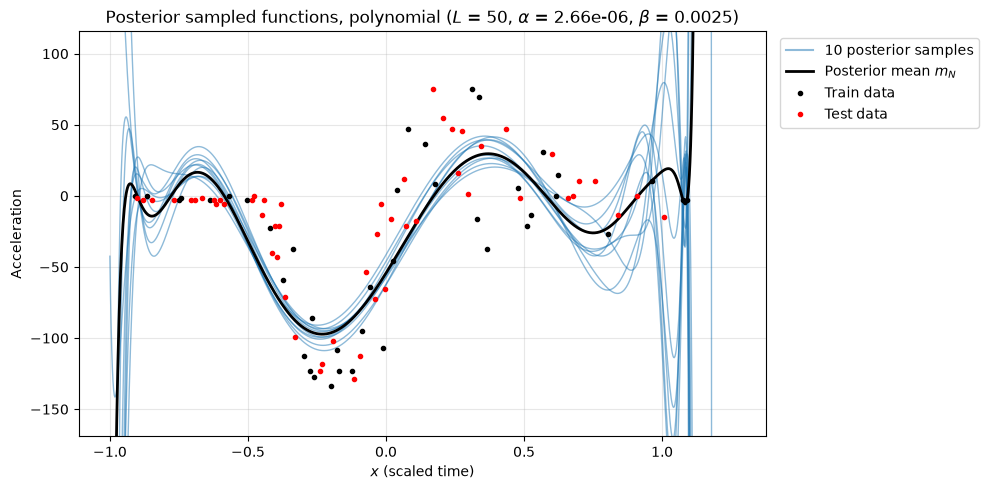

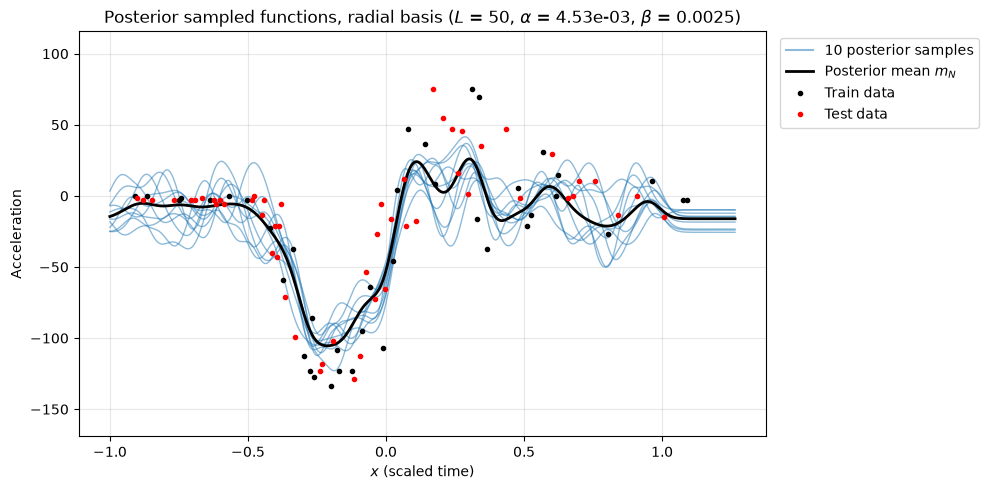

In [204]:
# Draw 10 posterior weight samples for the best-test polynomial and radial basis models (L = 50)
# (uses beta, L_map, best_test_alpha, best_test_alpha_rbf from the part 2 & 3 cells above)
np.random.seed(0)   # reproducible samples
n_samples = 10

def posterior(phi, y, a, b):
    ''' Posterior mean m_N and covariance S_N of the weights under a N(0, a^-1 I) prior '''
    S_inv = b * phi.T @ phi + a * np.eye(phi.shape[1])
    S_N = np.linalg.inv(S_inv)
    S_N = 0.5 * (S_N + S_N.T)                 # ensure symmetry for numerical stability
    m_N = b * S_N @ phi.T @ y                 # = (Phi^T Phi + (a/b) I)^-1 Phi^T y
    return m_N, S_N

post_models = {
    'polynomial': (basis_poly,   best_test_alpha),
    'radial basis': (basis_radial, best_test_alpha_rbf),
}

for name, (basis, a) in post_models.items():
    phi_tr = basis(x_train, L_map)
    phi_gr = basis(x_grid, L_map)
    m_N, S_N = posterior(phi_tr, y_train, a, beta)

    w_samples = np.random.multivariate_normal(m_N, S_N, size=n_samples)   # (n_samples, M)
    f_samples = phi_gr @ w_samples.T                                       # (G, n_samples)

    plt.figure(figsize=(10, 5))
    plt.plot(x_grid, f_samples, '-', color='tab:blue', alpha=0.5, lw=1)
    plt.plot([], [], '-', color='tab:blue', alpha=0.5, label=f'{n_samples} posterior samples')
    plt.plot(x_grid, phi_gr @ m_N, 'k-', lw=2, label='Posterior mean $m_N$')
    plt.plot(x_train, y_train, 'k.', label='Train data')
    plt.plot(x_test, y_test, 'r.', label='Test data')

    pad = 0.2 * (y_test.max() - y_test.min())
    plt.ylim(y_test.min() - pad, y_test.max() + pad)
    plt.xlabel('$x$ (scaled time)')
    plt.ylabel('Acceleration')
    plt.title(rf'Posterior sampled functions, {name} ($L$ = {L_map}, $\alpha$ = {a:.2e}, $\beta$ = {beta})')
    plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### Problem 2, part 5: Held-out point under the Bayesian models
Predict the held-out point (x = 57.6, y = 10.7) with the posterior mean of each best-test model from part 4, and compare the error to the posterior uncertainty at that x.

In [205]:
# Error on the held-out point for the best-test MAP models, plus posterior uncertainty there
# (uses x_out, y_out from Problem 1 part 4, and posterior / post_models from part 4)
print(f'Held-out point: x = {x_out_raw} (scaled {x_out[0]:.3f}), y = {y_out}\n')

for name, (basis, a) in post_models.items():
    m_N, S_N = posterior(basis(x_train, L_map), y_train, a, beta)
    phi_out = basis(x_out, L_map)[0]

    yhat_out = phi_out @ m_N
    rmse_out = np.sqrt((y_out - yhat_out)**2)             # RMSE of a single point = |error|

    # Posterior uncertainty at x_out: std of w^T phi(x) (the spread of the sampled functions),
    # and of the full predictive distribution, which also includes the noise variance 1/beta
    f_std    = np.sqrt(phi_out @ S_N @ phi_out)
    pred_std = np.sqrt(1/beta + phi_out @ S_N @ phi_out)

    print(f'{name:>12} (L = {L_map}, alpha = {a:.2e}): prediction = {yhat_out:9.3f}, RMSE = {rmse_out:8.3f}')
    print(f'{"":>12}   posterior std of w^T phi(x) = {f_std:9.3f}, predictive std (incl. noise) = {pred_std:8.3f}')
    print(f'{"":>12}   error is {rmse_out/pred_std:.2f} predictive std devs\n')

Held-out point: x = 57.6 (scaled 1.174), y = 10.7

  polynomial (L = 50, alpha = 2.66e-06): prediction = 11083.961, RMSE = 11073.261
               posterior std of w^T phi(x) = 188488.758, predictive std (incl. noise) = 188488.759
               error is 0.06 predictive std devs

radial basis (L = 50, alpha = 4.53e-03): prediction =   -16.087, RMSE =   26.787
               posterior std of w^T phi(x) =     5.452, predictive std (incl. noise) =   20.730
               error is 1.29 predictive std devs

